In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import utils
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
EPOCHS = 1000
LN10 = np.log(10)

mu, sigma = 0, 0.1
dim = 100
lam = 1
n_runs = 10
floor = 40 * LN10
rng = np.random.default_rng(seed=42)

utils.set_paper_style()

In [4]:
STYLE = {
    "CCD":   dict(color="#0072B2", ls="-",  lw=1.3),
    "ERate": dict(color="#000000", ls="--", lw=1.0),
    "PRate": dict(color="#D55E00", ls="-",  lw=1.3),
}

In [5]:
A = rng.normal(mu, sigma, (dim, dim))
b = rng.normal(mu, sigma, (dim, 1))

In [6]:
def rate_ccd(A): 
    """
    Compute rate for Cyclic Coordinate Descent (CCD) using the spectral radius.

    params:
        n: dimension
        c: off-diagonal value
    """

    D = np.diag(np.diag(A))
    L = -np.tril(A, -1)
    C = np.linalg.inv(D - L) @ L.T

    return -np.log(np.max(np.abs(np.linalg.eigvals(C))))

def erate_rcd(H):
    """
    Expected rate of RCD (uniform sampling, exact coordinate steps),
    per epoch: -n log rho(I - D^{-1}H / n). 
    """

    n = H.shape[0]
    D = np.diag(np.diag(H))

    return -n * np.log(np.max(np.abs(np.linalg.eigvals(np.identity(n)- np.linalg.inv(D) @ H / n))))


def run_ccd(epochs, x0, A, b):
    """
    Run CCD algorithms on general objective Ax - b norm sqaures
    """

    D = np.diag(np.diag(A))
    L = -np.tril(A, -1)
    C = np.linalg.inv(D - L) @ L.T

    x_star = np.linalg.solve(A, b)
    e = (x0  - x_star) / np.linalg.norm(x0 - x_star)
    errors = np.zeros(epochs + 1)

    for epoch in range(epochs):
        e = C @ e 
        norm = np.linalg.norm(e)
        e /= norm
        errors[epoch + 1] = errors[epoch] + np.log(norm) 

    return errors

def run_prcd(epochs, x0, H, c, n_runs, rng, probs=None):
    """
    Pathwise rate for RCD on f(x) = 0.5 x^T H x - c^T x.
    Per-epoch clock: one epoch = n random coordinate updates.

    params:
        H: Hessian (A_c for the A_c problem; A.T @ A for least squares)
        c: linear term (b for A_c; A.T @ b for least squares)
        probs: sampling distribution (None = uniform, i.e. RCDM(0);
               np.diag(H) / np.trace(H) gives RCDM(1))
    """

    n = H.shape[0]
    d = np.diag(H)
    x_star = np.linalg.solve(H, c)
    errors = np.zeros((n_runs, epochs + 1))

    for row in range(n_runs):
        e = (x0 - x_star) / np.linalg.norm(x0 - x_star)
        for epoch in range(epochs):
            g = H @ e                       # recompute every epoch
            for i in rng.choice(n, size=n, p=probs):
                delta = -g[i] / d[i]        # exact minimization in coordinate i
                e[i] += delta
                g += delta * H[:, i]        
            norm = np.linalg.norm(e)
            e /= norm
            errors[row, epoch + 1] = errors[row, epoch] + np.log(norm)

    return errors, errors.mean(axis=0), errors.std(axis=0)

In [8]:
def plot_algo(epochs, x0, H, c, n_runs, rng, floor=40 * LN10):
    """
    Plot log error vs epoch for CCD, RCD (individual paths, mean ± std),
    and the RCD expected-rate line, on f(x) = 0.5 x^T H x - c^T x.
    All rates are per epoch (n coordinate updates).

    params:
        epochs: number of epochs
        x0: initial vector (1-D, length n)
        H: Hessian (A_c, or A.T @ A for least squares)
        c: linear term (b, or A.T @ b for least squares)
        n_runs: number of RCD runs for the path rate
        rng: np.random.default_rng(seed)
        floor: log-error depth used to set the axis limits (default 40 ln 10)

    return:
        fig, ax
    """
    x0 = np.asarray(x0, float).ravel()
    c = np.asarray(c, float).ravel()

    ccd_rate = rate_ccd(H)
    rcd_erate = erate_rcd(H)
    x_coor = np.arange(epochs + 1)

    ccd_errors = run_ccd(epochs, x0, H, c)
    rcd_errors = -rcd_erate * x_coor
    prcd_errors, mean_prcd, std_prcd = run_prcd(epochs, x0, H, c, n_runs, rng)

    half = epochs // 2
    prcd_rates = -(prcd_errors[:, -1] - prcd_errors[:, half]) / (epochs - half)
    prcd_rate = prcd_rates.mean()
    prcd_se = prcd_rates.std(ddof=1) / np.sqrt(n_runs)

    fig, ax = plt.subplots(figsize=(4, 3))
    ax.plot(x_coor, ccd_errors, **STYLE["CCD"],
            label=f"CCD (Rate = {ccd_rate:.3g})")
    ax.plot(x_coor, rcd_errors, **STYLE["ERate"],
            label=f"Exact slope (ERate = {rcd_erate:.3g})")

    ax.plot(x_coor, prcd_errors.T, color=STYLE["PRate"]["color"], lw=0.3, alpha=0.3)
    ax.fill_between(x_coor, mean_prcd - std_prcd, mean_prcd + std_prcd,
                    color=STYLE["PRate"]["color"], alpha=0.25, lw=0)
    ax.plot(x_coor, mean_prcd, **STYLE["PRate"],
            label=f"RCD, mean ± std of {n_runs} runs\n(PRate = {prcd_rate:.3g} ± {prcd_se:.2g})")

    slowest = min(ccd_rate, rcd_erate, prcd_rate)
    xmax = epochs if slowest <= 0 else min(epochs, 1.1 * floor / slowest)
    ax.set_xlim(0, xmax)
    ax.set_ylim(-floor, 1)
    ax.set_xlabel(r"epoch $\ell$ ($n$ coordinate updates)")
    ax.set_ylabel(r"$\log\frac{\|x_\ell - x^\star\|}{\|x_0 - x^\star\|}$")
    ax.legend(loc="upper right")
    return fig, ax

### OLS objective function

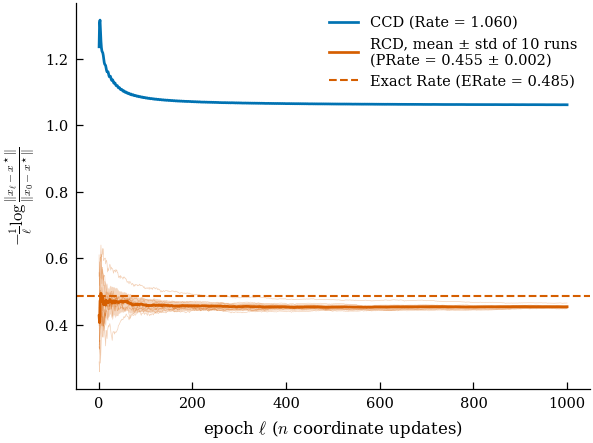

In [7]:
x_coor = np.arange(EPOCHS + 1)

b = np.asarray(b, float).ravel()
erate = erate_rcd(A.T @ A + lam * np.identity(dim))
ccd_rate = rate_ccd(A.T @ A + lam * np.identity(dim))
ccd_errors = run_ccd(EPOCHS, np.zeros((dim, 1)), A.T @ A + lam * np.identity(dim), A.T @ b)
prcd_errors, mean_prcd, std_prcd = run_prcd(EPOCHS, np.zeros(dim), A.T @ A + lam * np.identity(dim), A.T @ b, n_runs, rng)
                                            
half = EPOCHS // 2
prcd_rates = -(prcd_errors[:, -1] - prcd_errors[:, half]) / (EPOCHS - half)
prcd_rate = np.mean(prcd_rates)
prcd_se = prcd_rates.std(ddof=1) / np.sqrt(n_runs)
fig, ax = plt.subplots(figsize=(4, 3))

ax.plot(x_coor[1:], -ccd_errors[1:] / x_coor[1:], **STYLE["CCD"], 
        label=f"CCD (Rate = {ccd_rate:.3f})")

ax.plot(x_coor[1:], -prcd_errors[:, 1:].T/ x_coor[1:].reshape((EPOCHS, -1)), 
        color=STYLE["PRate"]["color"], lw=0.3, alpha=0.3)
ax.fill_between(x_coor[1:], -(mean_prcd[1:] - std_prcd[1:]) / (x_coor[1:]), -(mean_prcd[1:] + std_prcd[1:]) / (x_coor[1:]), 
                color=STYLE["PRate"]["color"], alpha=0.25, lw=0)
ax.plot(x_coor[1:], -mean_prcd[1:] / x_coor[1:], **STYLE["PRate"], 
        label=f"RCD, mean ± std of {n_runs} runs\n(PRate = {prcd_rate:.3f} ± {prcd_se:.3f})")

ax.axhline(erate, ls="--", lw=1, color=STYLE["PRate"]["color"],
           label=f"Exact Rate (ERate = {erate:.3g})")


ax.set_xlabel(r"epoch $\ell$ ($n$ coordinate updates)")
ax.set_ylabel(r"$-\frac{1}{\ell}\log\frac{\|x_\ell - x^\star\|}{\|x_0 - x^\star\|}$")
ax.legend(loc="upper right")

(<Figure size 600x450 with 1 Axes>,
 <Axes: xlabel='epoch $\\ell$ ($n$ coordinate updates)', ylabel='$\\log\\frac{\\|x_\\ell - x^\\star\\|}{\\|x_0 - x^\\star\\|}$'>)

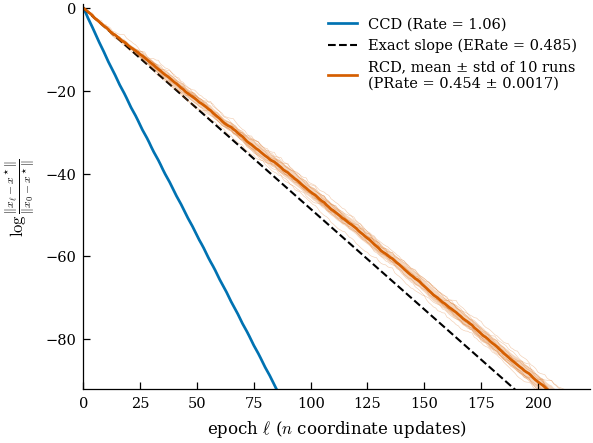

In [9]:
H = A.T @ A + lam * np.identity(dim)
plot_algo(EPOCHS, np.zeros(dim), H, A.T @ b, n_runs, rng)

### Logistic with regularization

In [11]:
from logreg import make_logreg, plot_algo_logreg

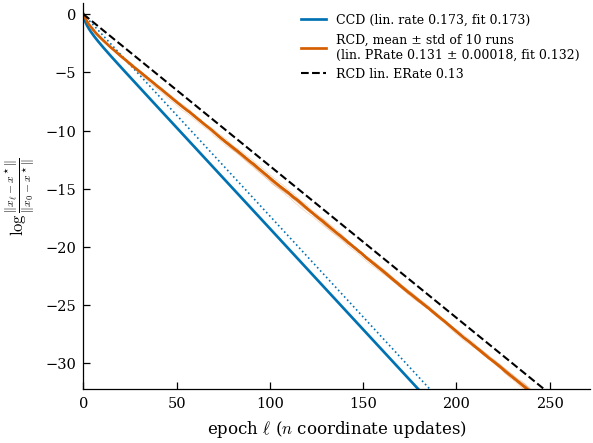

In [14]:
SEED = 0
m, n, lam = 1000, 100, 1e-3
EPOCHS, n_runs = 300, 10
 
A, b = make_logreg(m, n, lam, np.random.default_rng(SEED))
fig, ax = plot_algo_logreg(EPOCHS, np.zeros(n), A, b, lam, n_runs,
                           np.random.default_rng(SEED + 1))